In [ ]:
# This will let you upload the file from your computer
from google.colab import files
uploaded = files.upload()

Saving finaccess2024_datasprint.xlsx to finaccess2024_datasprint.xlsx


In [ ]:

# All libraries needed for this project

# Data handling
import pandas as pd
import numpy as np
# Visualisation
import matplotlib.pyplot as plt
import seaborn as sns
# Machine learning - preprocessing
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
# Machine learning - models
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
# Machine learning - evaluation
from sklearn.metrics import f1_score, classification_report, ConfusionMatrixDisplay

In [ ]:
# Loading the dasaset into a DataFrame
df = pd.read_excel("finaccess2024_datasprint.xlsx")

In [ ]:
# Showing the first 5 rows of the dataset
df.head()

,county,location_type,Sex,Age,household_size,education_level,marital_status,monthly_income,Savings_formal,Savings_informal,...,nfhi_11,nfhi_12,nfhi_13,accessto_13k_1month,not_difficult,financial_status,fl_score,prodsum1,barriers_bank,has_disability
0,Garissa,Urban,Female,26-35,5,Completed technical training after secondary s...,Married/Living with partner,30000,Non-usage,Non-usage,...,Yes,Yes,Yes,Yes,No,Stayed the same,All correct,3,NaN,Without Disability
1,Garissa,Urban,Female,Above 55,11,"""None """,Married/Living with partner,10000,Non-usage,Non-usage,...,No,No,Yes,No,No,Worsened,Two correct,1,Affordability,Without Disability
2,Busia,Urban,Female,26-35,2,"""Primary completed""",Divorced/separated,3000,Usage,Usage,...,Yes,No,No,No,No,Improved,All correct,5,Affordability,Without Disability
3,Kiambu,Urban,Male,18-25,1,"""Some secondary""",Single/Never Married,10000,Usage,Non-usage,...,No,No,No,Yes,No,Improved,All correct,4,Affordability,Without Disability
4,Murang'a,Urban,Female,18-25,1,Some technical training after secondary school,Single/Never Married,10000,Usage,Non-usage,...,Yes,Yes,Yes,Yes,Yes,Improved,All correct,5,NaN,Without Disability


In [ ]:
# The shape of the dataset (No of rows and columns)
df.shape

(20871, 28)

We note that there are 20.871 rows and 28 columns in the dataset

In [ ]:
# Shows statistics for numerical columns
df.describe()

,household_size,monthly_income,prodsum1
count,20871.000000,20871.000000,20871.000000
mean,4.215946,9702.774280,3.936563
std,2.512658,15423.366592,3.227992
min,1.000000,100.000000,0.000000
25%,2.000000,2500.000000,1.000000
50%,4.000000,5000.000000,3.000000
75%,6.000000,10000.000000,6.000000
max,20.000000,200000.000000,22.000000


In [ ]:
# Shows all column names and what data type each one is
df.dtypes

,0
county,object
location_type,object
Sex,object
Age,object
household_size,int64
education_level,object
marital_status,object
monthly_income,int64
Savings_formal,object
Savings_informal,object


In [ ]:
# Shows columns with missing values
missing = df.isnull().sum()
print(missing[missing > 0])

barriers_bank    5734
dtype: int64


We note that the coulumn (barriers_bank) had 5734 missing values



In [ ]:
# Counts how many people fall into each category (Our Target Variable)
print(df['financial_status'].value_counts())

# Also show as percentages
print("\nAs percentages:")
print(df['financial_status'].value_counts(normalize=True) * 100)

financial_status
Worsened           10981
Stayed the same     5609
Improved            4281
Name: count, dtype: int64

As percentages:
financial_status
Worsened           52.613674
Stayed the same    26.874611
Improved           20.511715
Name: proportion, dtype: float64


We come to see that
Worsened: ~52.6%
Stayed the same: ~26.9%
Improved: ~20.5%

In [ ]:
# Counting each category
counts = df['financial_status'].value_counts()

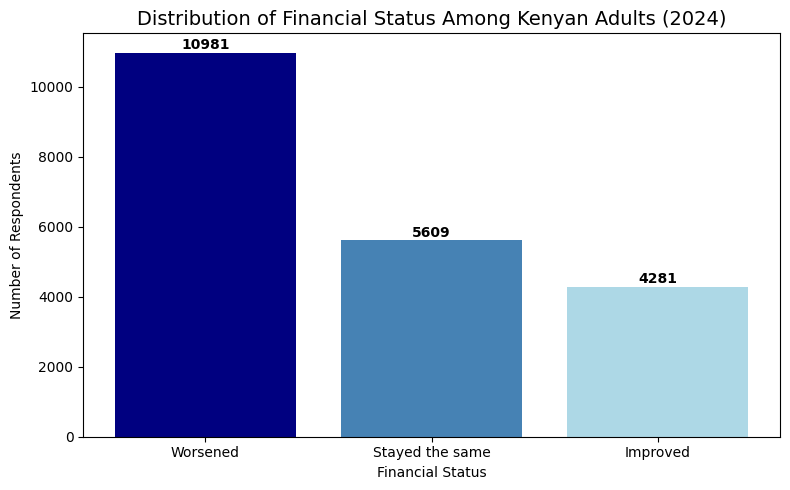

In [ ]:
# A bar chart illustrating the distribution of financial status among Kenyan Adults (2024)
plt.figure(figsize=(8, 5))
plt.bar(counts.index, counts.values, color=['navy', 'steelblue', 'lightblue'])

plt.title('Distribution of Financial Status Among Kenyan Adults (2024)', fontsize=14)
plt.xlabel('Financial Status')
plt.ylabel('Number of Respondents')

for i, v in enumerate(counts.values):
    plt.text(i, v + 100, str(v), ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

## Target Variable Distribution

The target variable is imbalanced across three classes:
- **Worsened**: 10,981 respondents (52.6%)
- **Stayed the same**: 5,609 respondents (26.9%)
- **Improved**: 4,281 respondents (20.5%)

The majority class (Worsened) is roughly 2.5 times larger than the minority
class (Improved). There are direct implications for this while modelling — a naive
classifier predicting "Worsened" for all observations would achieve ~52.6%
accuracy while providing no predictive value for the other two classes.
Because of this, **weighted F1-score** is used as the primary evaluation
metric and class imbalance will be addressed during preprocessing
(e.g. `class_weight = 'balanced'`).

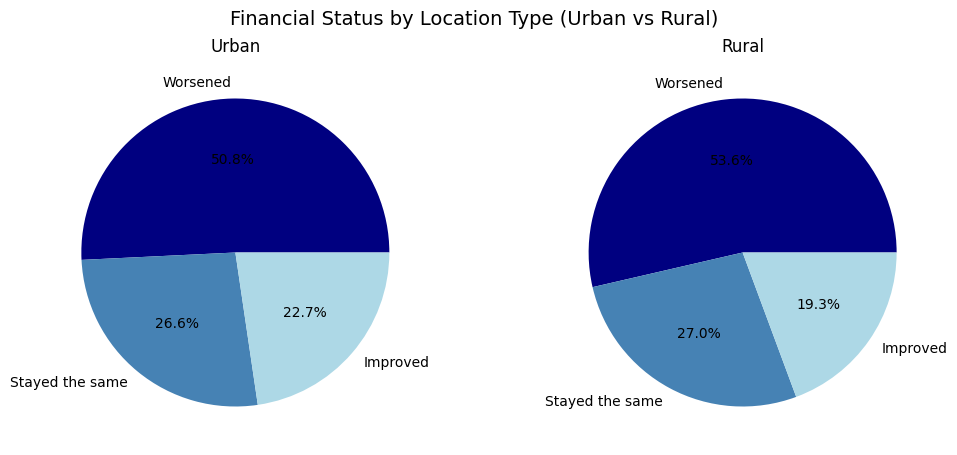

In [ ]:
# A pie chart illustrating financial status by Location Type (Urban vs Rural)
urban = df[df['location_type'] == 'Urban']['financial_status'].value_counts()
rural = df[df['location_type'] == 'Rural']['financial_status'].value_counts()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.pie(urban.values, labels=urban.index, colors=['navy', 'steelblue', 'lightblue'], autopct='%1.1f%%')
ax1.set_title('Urban')

ax2.pie(rural.values, labels=rural.index, colors=['navy', 'steelblue', 'lightblue'], autopct='%1.1f%%')
ax2.set_title('Rural')

fig.suptitle('Financial Status by Location Type (Urban vs Rural)', fontsize=14)

plt.show()


## Financial Status by Location Type (Urban vs Rural)

This breakdown reveals that financial
deterioration is widespread across both settings, but slightly more severe
in rural areas:

`Worsened` - 50.8% urban, 53.6% rural

`Stayed the same` - 26.6% urban, 27.0% rural

`Improved` - 22.7% urban, 19.3% rural

Rural respondents are roughly 2.8 percentage points more likely to report
worsening financial situations and about 3.4 percentage points less likely
to report improvement compared to urban respondents.

While it's not exactly that big a gap, it is consistent with the broader literature
on rural financial vulnerability in Kenya where rural households tend to have
lower income stability, higher exposure to agricultural shocks and more
limited access to formal financial services. The `location_type` variable
may therefore carry some predictive signal, but its effect is likely
moderated by correlated variables such as `monthly_income`,
`experienced_shock` and `formal_service_use`.

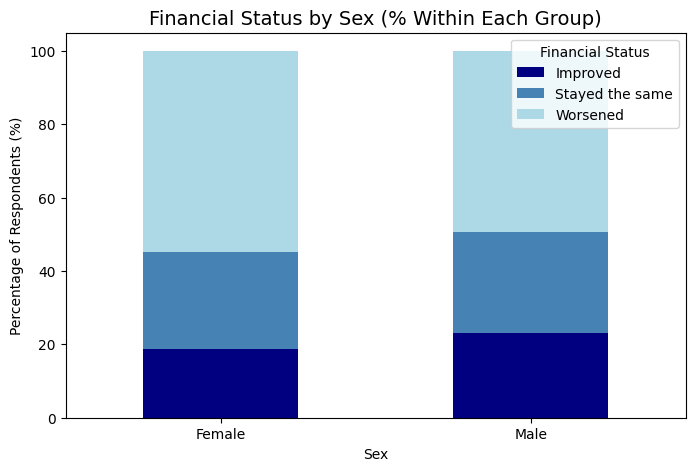

In [ ]:
# A stacked bar chart illustrating Financial Status by Sex

sex_proportions = df.groupby('Sex')['financial_status'].value_counts(normalize=True).unstack() * 100

sex_proportions.plot(kind='bar', stacked=True, figsize=(8, 5), color=['navy', 'steelblue', 'lightblue'])

plt.title('Financial Status by Sex (% Within Each Group)', fontsize=14)
plt.xlabel('Sex')
plt.ylabel('Percentage of Respondents (%)')
plt.xticks(rotation=0)
plt.legend(title='Financial Status')

plt.show()

## Financial Status by Sex (Proportions)

Looking at within-group proportions gives a fairer gender comparison than
raw counts. The stacked bar chart (which gives the percentage within each sex group) shows:

`Worsened:` ~55% female, ~49% male

`Stayed the same:` ~26% female, ~27% male

`Improved:` ~19% female, ~24% male

We can see a clear gender gap. Female respondents are approximately
6 percentage points more likely to report financial deterioration and
about 5 percentage points less likely to report improvement compared to
male respondents. The "Stayed the same" share is nearly identical across
both groups, suggesting that the gender divide is specifically between
"Worsened" and "Improved" rather than a uniform shift across all outcomes.

This is as is seen with documented gender disparities in Kenya's financial
landscape. Women are more likely to be in informal or unpaid work, tend
to have lower average incomes and face greater barriers to formal financial
services including ID requirements and collateral constraints. The `Sex`
variable carries a predictive signal, though its effect is likely partially
mediated by correlated variables such as `monthly_income`, `Loan_informal`
and `formal_service_use`.

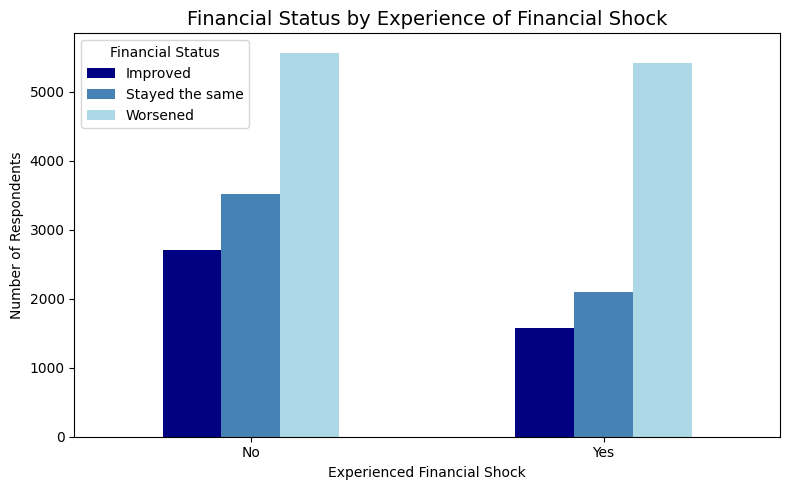

In [ ]:
# A bar chart illustrating financial status by Whether a Financial Shock was Experienced

shock_counts = df.groupby(['experienced_shock', 'financial_status']).size().unstack()

shock_counts.plot(kind='bar', figsize=(8, 5), color=['navy', 'steelblue', 'lightblue'])

plt.title('Financial Status by Experience of Financial Shock', fontsize=14)
plt.xlabel('Experienced Financial Shock')
plt.ylabel('Number of Respondents')

plt.xticks(rotation=0)
plt.legend(title='Financial Status')

plt.tight_layout()
plt.show()

## Financial Status by Experience of Financial Shock

This chart shows how experiencing a financial shock in the past year
relates to `financial_status`. We've used raw counts so within-group
proportions are more meaningful for comparison.

Approximate counts:

`Worsened:` ~5,550 no shock, ~5,400 experienced shock          
`Stayed the same:` ~3,520 no shock, ~2,100 experienced shock           
`Improved:` ~2,720 no shock, ~1,620 experienced shock           

The key observation here is not just that "Worsened" dominates both groups, but that the ratio between "Improved" and "Worsened" shifts
noticeably. Among those who did not experience a shock, the "Improved" and
"Stayed the same" bars are relatively larger compared to the group that experienced shock.
Among those who did experience a shock, "Worsened" is even more dominant,
with "Improved" dropping significantly.

From this, we see that `experienced_shock` is a meaningful predictor of financial
deterioration. Shocks, whether from job loss, illness, drought or
unexpected expenses, appear to compress the likelihood of financial
improvement and push outcomes toward the negative end. This variable is
likely to carry strong predictive weight in the model.

/tmp/ipykernel_6452/3666289217.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='financial_status', y='monthly_income', palette=['navy', 'steelblue', 'lightblue'])


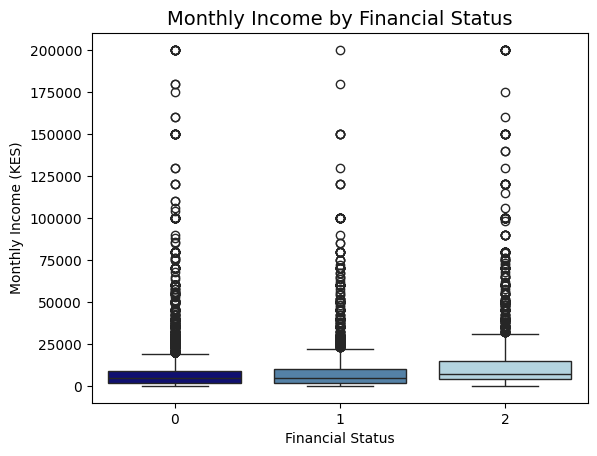

In [ ]:
# A box plot illustrating Monthly Income by Financial Status

sns.boxplot(data=df, x='financial_status', y='monthly_income', palette=['navy', 'steelblue', 'lightblue'])

plt.title('Monthly Income by Financial Status', fontsize=14)
plt.xlabel('Financial Status')
plt.ylabel('Monthly Income (KES)')

plt.show()

## Monthly Income by Financial Status

The boxplot shows the distribution of `monthly_income` (KES) across the
three financial status groups:

- **Medians are low and close across all three groups.** All three boxes sit
  near the bottom of the scale, with medians likely in the KES 5,000–10,000
  range. This supports the broader income reality in Kenya that tells us the majority of
  surveyed adults are low-income regardless of whether their situation improved
  or worsened.

- **The "Improved" group has a visibly higher box.** The interquartile range
  (IQR) for "Improved" sits noticeably higher than both "Worsened" and "Stayed
  the same", suggesting that those who reported improvement tend to have
  somewhat higher baseline incomes. Higher income can be seen as a buffer as it gives
  more capacity to save, absorb shocks and access financial services.

- **Outliers are present in all three groups**, with some respondents reporting
  incomes of up to KES 200,000. These high-income outliers appear across all
  categories, indicating that even high earners are not immune to financial
  deterioration, but it is worth noting that they are less concentrated in "Worsened".

- **"Worsened" has the lowest and most compressed box**, consistent with the
  idea that low-income individuals face a greater vulnerability to financial
  shocks and have fewer resources to recover.

Overall, `monthly_income` seems to have a moderate positive relationship
with financial improvement, but the overlap between the groups is quite big.
Income alone does not determine financial outcomes but together
with shock exposure, debt status and access to formal services, can tell us more.

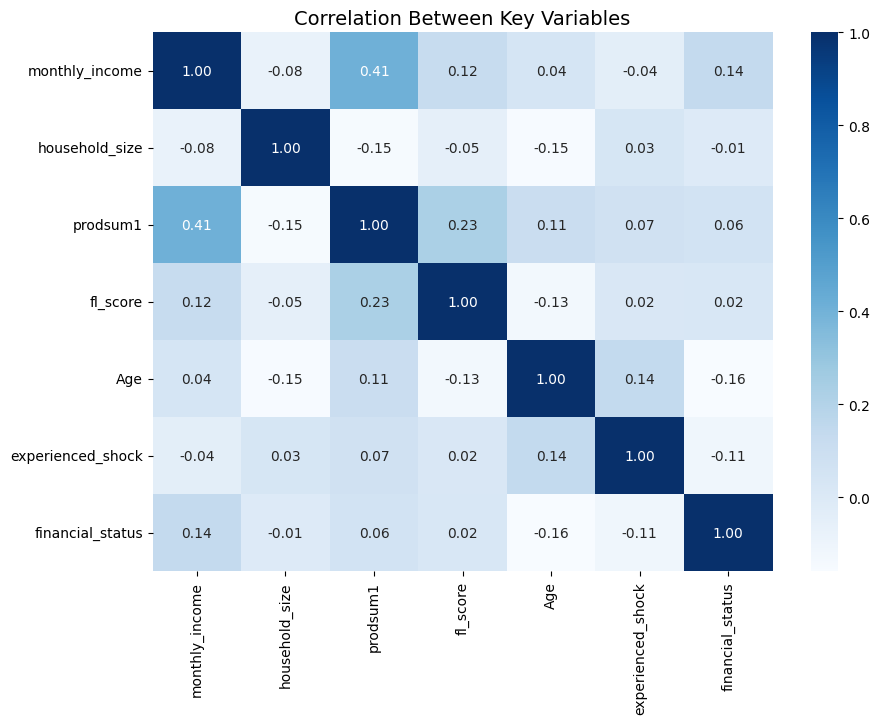

In [ ]:
# A correlation heatmap illustrating the correlation between Key Variables

cols_for_heatmap = [
    'monthly_income', 'household_size', 'prodsum1',
    'fl_score', 'Age', 'experienced_shock', 'financial_status'
]

correlation = df[cols_for_heatmap].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='Blues')

plt.title('Correlation Between Key Variables', fontsize=14)

plt.show()

## Correlation Between Key Variables

This expanded correlation matrix includes the encoded target variable
`financial_status` alongside all numeric and ordinal features, allowing
us to assess which variables have the strongest linear relationship with
the outcome.

Key observations:

**Correlations with `financial_status`:**

monthly_income: `0.14`        
Age: `-0.16`       
experienced_shock: `-0.11`       
prodsum1: `0.06`        
fl_score: `0.02`        
household_size: `-0.01`       

- **Age (r = -0.16)** has the strongest linear correlation with
  `financial_status` among all variables. The negative sign indicates
  that older respondents tend toward worse financial outcomes — this could
  reflect reduced income-earning capacity, higher healthcare costs, or
  greater exposure to economic shocks over time.

- **monthly_income (r = 0.14)** is positively correlated with financial
  status, confirming the earlier boxplot finding — higher income is
  associated with better outcomes, though the relationship is modest.

- **experienced_shock (r = -0.11)** is negatively correlated, consistent
  with the earlier EDA finding that shock exposure pushes outcomes toward
  "Worsened".

- **prodsum1, fl_score, and household_size** show very weak linear
  correlations with the target (all ≤ 0.06). This does not necessarily
  mean these variables are unimportant — non-linear models like Random
  Forest may still extract predictive signal from them.

**Other notable relationships:**
- `monthly_income` vs `prodsum1` (r = 0.41) remains the strongest
  feature-to-feature correlation, confirming the earlier finding.
- `prodsum1` vs `fl_score` (r = 0.23) suggests that financially literate
  individuals tend to use more financial products.
- `Age` vs `experienced_shock` (r = 0.14) indicates older respondents
  are slightly more likely to have experienced a financial shock.

Overall, no feature pair shows a correlation high enough to raise
multicollinearity concerns (all below 0.5), so all variables can be
retained for modelling.

## Data Cleaning and Encoding

In [ ]:
# Handling missing values
df['barriers_bank'] = df['barriers_bank'].fillna('No barrier')

print('Missing values in barriers_bank:', df['barriers_bank'].isnull().sum())

Missing values in barriers_bank: 0


The barriers_bank column contains 5734 missing values. The participant brief notes these are individuals who already have bank accounts, meaning no barrier applies to them. We replace these blanks with a explicit 'No barrier' category string. This preserves the logical structure of the dataset for our machine learning model and ensures our final missing value count drops to 0

In [ ]:
# Checking all the unique values in each text column to decide on the kind of encoding to use
text_columns = df.select_dtypes(include='object').columns
for col in text_columns:
    print(f'{col}: {df[col].nunique()} unique values')
    print(df[col].unique(), '\n')

county: 47 unique values
['Garissa' 'Busia' 'Kiambu' "Murang'a" 'Kilifi' 'Meru' 'Kisumu' 'Baringo'
 'Isiolo' 'Embu' 'Mombasa' 'Elgeyo-Marakwet' 'Homabay' 'Migori' 'Siaya'
 'West Pokot' 'Nyeri' 'Bomet' 'Makueni' 'Uasin Gishu' 'Bungoma' 'Nakuru'
 'Kakamega' 'Kwale' 'Kitui' 'Mandera' 'Nairobi City' 'Machakos'
 'Tharaka-Nithi' 'Nyandarua' 'Marsabit' 'Kirinyaga' 'Kericho' 'Kisii'
 'Taita-Taveta' 'Vihiga' 'Trans Nzoia' 'Narok' 'Kajiado' 'Laikipia'
 'Nandi' 'Lamu' 'Turkana' 'Samburu' 'Tana River' 'Wajir' 'Nyamira'] 

location_type: 2 unique values
['Urban' 'Rural'] 

Sex: 2 unique values
['Female' 'Male'] 

Age: 6 unique values
['26-35' 'Above 55' '18-25' '36-45' '46-55' '16-17'] 

education_level: 13 unique values
['Completed technical training after secondary school' '"None "'
 '"Primary completed"' '"Some secondary"'
 'Some technical training after secondary school' '"Secondary completed "'
 '"Some primary "' '"University completed "' '"Other (Specify) "'
 'Some university' 95 '"Refused to

In [ ]:
# We decided to drop county because location_type already captures geographic differences. 47 dummy columns would add noise to the model
df = df.drop('county', axis=1)

# We cleaned education_level by removing quotation marks and extra spaces from its values
df['education_level'] = df['education_level'].str.replace('"', '').str.strip()

# We grouped refused/unknown responses into one category
df['education_level'] = df['education_level'].replace({
    "Refused to Answer (DO NOT READ OUT)": "Unknown",
    "Don't know (DO NOT READ OUT)": "Unknown",
    "Other (Specify)": "Unknown",
    "95": "Unknown"
})

# We cleaned marital_status by placing unknown in place of unclear answers
df['marital_status'] = df['marital_status'].replace({
    "Don't know   (DO NOT READ OUT)": "Unknown",
    "Refused to Answer(DO NOT READ OUT)": "Unknown"
})

# We label encoded all binary columns (columns that could have either of 2 unique values)
binary_cols = [
    'location_type', 'Sex', 'Savings_formal', 'Savings_informal',
    'Loan_formal', 'Loan_informal', 'defaulted', 'formal_service_use',
    'mobile_money_access', 'mobile_ownership_1', 'experienced_shock',
    'nfhi_11', 'nfhi_12', 'nfhi_13', 'accessto_13k_1month',
    'not_difficult', 'has_disability'
]

le = LabelEncoder()
for col in binary_cols:
    df[col] = le.fit_transform(df[col])

# We manually encoded columns that could have more than two unique variables

# fl_score: None correct=0, One=1, Two=2, All=3
fl_score_map = {
    'None correct': 0,
    'One correct': 1,
    'Two correct': 2,
    'All correct': 3
}
df['fl_score'] = df['fl_score'].map(fl_score_map)

# Age is encoded in an ascending order
age_map = {
    '16-17': 0,
    '18-25': 1,
    '26-35': 2,
    '36-45': 3,
    '46-55': 4,
    'Above 55': 5
}
df['Age'] = df['Age'].map(age_map)

# We made dummy columns out of multi-category column values
multi_cols = ['barriers_mobile_money', 'barriers_bank', 'marital_status', 'education_level']
df = pd.get_dummies(df, columns=multi_cols)

# We gave the target variable column values numerical equivalences
status_map = {
    'Worsened': 0,
    'Stayed the same': 1,
    'Improved': 2
}
df['financial_status'] = df['financial_status'].map(status_map)

# Printing the cleaned and encoded dataset
print('Dataset shape after encoding:', df.shape)
print('\nAny remaining text columns:')
print(df.select_dtypes(include='object').columns.tolist())
print('\nFirst 3 rows:')
df.head(3)

Dataset shape after encoding: (20871, 58)

Any remaining text columns:
[]

First 3 rows:


,location_type,Sex,Age,household_size,monthly_income,Savings_formal,Savings_informal,Loan_formal,Loan_informal,defaulted,...,education_level_Completed technical training after secondary school,education_level_None,education_level_Primary completed,education_level_Secondary completed,education_level_Some primary,education_level_Some secondary,education_level_Some technical training after secondary school,education_level_Some university,education_level_University completed,education_level_Unknown
0,1,0,2,5,30000,0,0,0,1,0,...,True,False,False,False,False,False,False,False,False,False
1,1,0,5,11,10000,0,0,0,0,0,...,False,True,False,False,False,False,False,False,False,False
2,1,0,2,2,3000,1,1,0,0,0,...,False,False,True,False,False,False,False,False,False,False


## Building Models

In [ ]:
# FEATURE ENGINEERING

# Feature 1 - Vulnerability Score
df['vulnerability_score'] = (
    df['experienced_shock'] +
    df['defaulted'] +
    (1 - df['nfhi_11']) +
    (1 - df['nfhi_12']) +
    (1 - df['nfhi_13'])
)

# Feature 2 - Financial Access Score
df['access_score'] = (
    df['mobile_money_access'] +
    df['mobile_ownership_1'] +
    df['Savings_formal'] +
    df['formal_service_use'] +
    df['accessto_13k_1month']
)

# Feature 3 - Income Band
df['income_band'] = pd.cut(
    df['monthly_income'],
    bins=[0, 5000, 20000, float('inf')],
    labels=[0, 1, 2]
).astype(int)

# Feature 4 - Dual Debt Flag
df['dual_debt'] = (
    (df['Loan_formal'] == 1) &
    (df['Loan_informal'] == 1)
).astype(int)

# Confirming new columns were added
print('New dataset shape:', df.shape)
print('\nNew features added:')
print(df[['vulnerability_score', 'access_score', 'income_band', 'dual_debt']].head())

New dataset shape: (20871, 62)

New features added:
   vulnerability_score  access_score  income_band  dual_debt
0                    0             4            2          0
1                    2             3            1          0
2                    3             4            0          0
3                    4             5            1          1
4                    0             5            1          0


The iLab guidance stated: "A well engineered feature beats a complex algorithm" - so before concluding we created four new features from existing columns:
1. vulnerability_score - combines shock, default, food insecurity and debt stress into one composite score
2. access_score - combines mobile money, savings and formal service access into one composite score
3. income_band - groups monthly income into Low/Mid/High
4. dual_debt - flags respondents with both formal and informal loans simultaneously

In [ ]:
# TRAIN/TEST SPLIT

# Separating features (X) from target (y)
# X is everything the model uses to make predictions
# y is the answer we are trying to predict
X = df.drop('financial_status', axis=1)
y = df['financial_status']

# Splitting into training and test sets
# test_size=0.2 → 20% for testing, 80% for training
# random_state=42 → makes the split reproducible every time
# stratify=y → keeps the same proportion of Worsened/Same/Improved in both training and test sets since our data is imbalanced
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Confirming the split worked correctly
print('Full dataset:', df.shape)
print('Training set:', X_train.shape)
print('Test set:', X_test.shape)
print('\nTarget distribution in training set:')
print(y_train.value_counts(normalize=True) * 100)
print('\nTarget distribution in test set:')
print(y_test.value_counts(normalize=True) * 100)

Full dataset: (20871, 62)
Training set: (16696, 61)
Test set: (4175, 61)

Target distribution in training set:
financial_status
0    52.611404
1    26.874701
2    20.513896
Name: proportion, dtype: float64

Target distribution in test set:
financial_status
0    52.622754
1    26.874251
2    20.502994
Name: proportion, dtype: float64


# MODEL 1 - DECISION TREE (BASELINE)

Weighted F1 Score: 0.4313084744990604

Classification Report:
              precision    recall  f1-score   support

           0       0.57      0.54      0.55      2197
           1       0.29      0.31      0.30      1122
           2       0.28      0.29      0.29       856

    accuracy                           0.43      4175
   macro avg       0.38      0.38      0.38      4175
weighted avg       0.44      0.43      0.43      4175



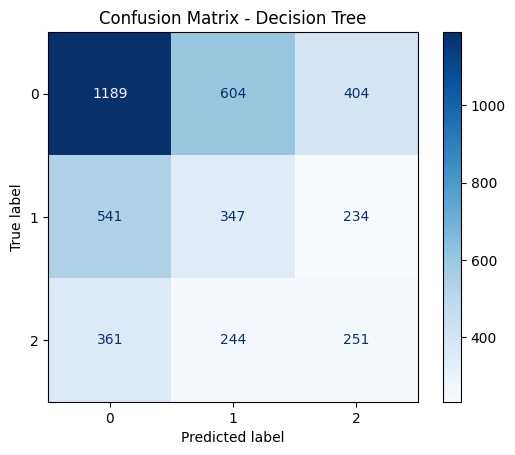

In [ ]:
# BUILDING AND EVALUATING THE FIRST MODEL (DECISION TREE)

model = DecisionTreeClassifier(class_weight='balanced', random_state=42)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print('Weighted F1 Score:', f1_score(y_test, y_pred, average='weighted'))
print('\nClassification Report:')

print(classification_report(y_test, y_pred)) # 0=Worsened, 1=Stayed the same, 2=Improved

# Confusion matrix
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')
plt.title('Confusion Matrix - Decision Tree')
plt.show()

We started with a Decision Tree as our baseline model which gave us a reference point to measure whether more complex models actually improve performance


# MODEL 1B - DECISION TREE (LIMITED DEPTH)

Weighted F1 Score: 0.48882774988058425

Classification Report:
              precision    recall  f1-score   support

           0       0.66      0.56      0.61      2197
           1       0.37      0.31      0.33      1122
           2       0.32      0.52      0.39       856

    accuracy                           0.48      4175
   macro avg       0.45      0.46      0.44      4175
weighted avg       0.51      0.48      0.49      4175



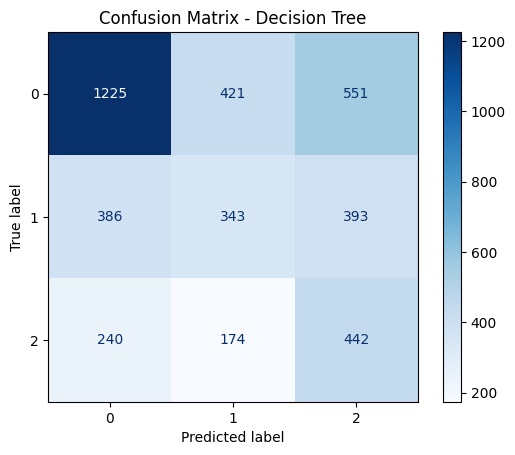

In [ ]:
model = DecisionTreeClassifier(
    class_weight='balanced',
    random_state=42,
    max_depth=5
    )

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print('Weighted F1 Score:', f1_score(y_test, y_pred, average='weighted'))
print('\nClassification Report:')

print(classification_report(y_test, y_pred)) # 0=Worsened, 1=Stayed the same, 2=Improved

# Confusion matrix
ConfusionMatrixDisplay.from_estimator(model, X_test, y_test, cmap='Blues')
plt.title('Confusion Matrix - Decision Tree')
plt.show()

The baseline Decision Tree scored 0.43 - relatively low so we suspected overfitting - the tree was growing too deep and memorising training data rather than learning patterns.
Limiting max_depth to 5 forces the model to learn more general patterns - this improved F1 to 0.49

# MODEL 2 - LOGISTIC REGRESSION

Logistic Regression F1 Score: 0.49385191879298124

Classification Report:
              precision    recall  f1-score   support

           0       0.68      0.53      0.59      2197
           1       0.38      0.36      0.37      1122
           2       0.32      0.53      0.40       856

    accuracy                           0.48      4175
   macro avg       0.46      0.47      0.45      4175
weighted avg       0.53      0.48      0.49      4175



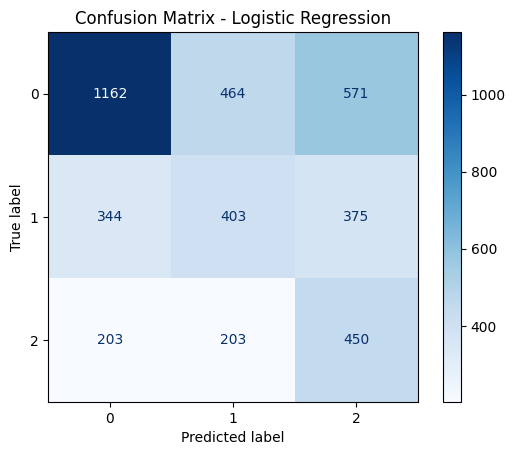

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

lr_model = LogisticRegression(
    class_weight='balanced',
    random_state=42,
    max_iter=1000
)

lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

print('Logistic Regression F1 Score:', f1_score(y_test, y_pred_lr, average='weighted'))
print('\nClassification Report:')
print(classification_report(y_test, y_pred_lr))

ConfusionMatrixDisplay.from_estimator(lr_model, X_test_scaled, y_test, cmap='Blues')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()

Despite the name, Logistic Regression is a classification model not a regression model we tried it because it is highly interpretable and the competition brief specifically suggested it. It also handles class imbalance differently to Decision Trees
Notable finding - it achieved better recall for the Improved class (54%) compared to Decision Tree, suggesting it is more balanced across all three classes even if overall F1 is similar at 0.49

# MODEL 3 - RANDOM FOREST

Random Forest F1 Score: 0.5050044191085964

Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.86      0.70      2197
           1       0.44      0.21      0.29      1122
           2       0.42      0.22      0.29       856

    accuracy                           0.55      4175
   macro avg       0.48      0.43      0.43      4175
weighted avg       0.52      0.55      0.51      4175



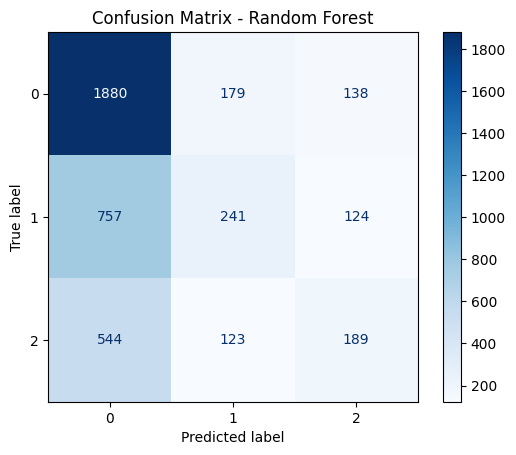

In [ ]:
rf_model = RandomForestClassifier(
    class_weight='balanced',
    random_state=42,
    n_estimators=100
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print('Random Forest F1 Score:', f1_score(y_test, y_pred_rf, average='weighted'))
print('\nClassification Report:')
print(classification_report(y_test, y_pred_rf))

ConfusionMatrixDisplay.from_estimator(rf_model, X_test, y_test, cmap='Blues')
plt.title('Confusion Matrix - Random Forest')
plt.show()

Random Forest builds 100 Decision Trees independently and combines their predictions
This reduces overfitting compared to a single tree because no single tree dominates the final prediction
It improved weighted F1 to 0.51 but the confusion matrix revealed heavy bias toward predicting Worsened (86% recall) while struggling with Stayed same (21%) and Improved (22%)
This pointed to class imbalance as the core problem

# MODEL 4 - RANDOM FOREST + SMOTE

Before SMOTE:
financial_status
0    8784
1    4487
2    3425
Name: count, dtype: int64

After SMOTE:
financial_status
0    8784
1    8784
2    8784
Name: count, dtype: int64

Random Forest + SMOTE F1 Score: 0.5036182553613118

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.72      0.66      2197
           1       0.38      0.29      0.33      1122
           2       0.36      0.31      0.33       856

    accuracy                           0.52      4175
   macro avg       0.45      0.44      0.44      4175
weighted avg       0.50      0.52      0.50      4175



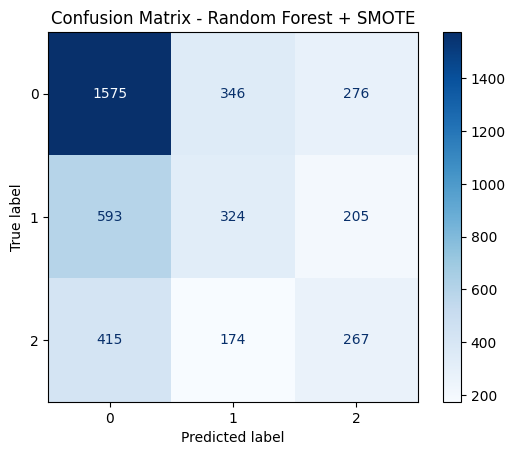

In [ ]:
!pip install imbalanced-learn --quiet

from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train, y_train)

print('Before SMOTE:')
print(y_train.value_counts())
print('\nAfter SMOTE:')
print(y_train_smote.value_counts())

rf_smote = RandomForestClassifier(
    random_state=42,
    n_estimators=100
)

rf_smote.fit(X_train_smote, y_train_smote)
y_pred_smote = rf_smote.predict(X_test)

print('\nRandom Forest + SMOTE F1 Score:', f1_score(y_test, y_pred_smote, average='weighted'))
print('\nClassification Report:')
print(classification_report(y_test, y_pred_smote))

ConfusionMatrixDisplay.from_estimator(rf_smote, X_test, y_test, cmap='Blues')
plt.title('Confusion Matrix - Random Forest + SMOTE')
plt.show()

To address the class imbalance problem identified in Model 3 we applied SMOTE (Synthetic Minority Oversampling Technique)
SMOTE artificially creates new examples of the minority# classes (Stayed same and Improved) in the training set to give the model more balanced data to learn from
After SMOTE the training set had equal representation:
8784 examples of each class
eighted F1 dropped slightly from 0.51 to 0.50
From this we note that SMOTE did not improve performance and marginally reduced it
This suggests the Random Forest with class_weight='balanced' was already handling the imbalance adequately
Artificially generating synthetic examples added noise rather than useful signal to the training data


# MODEL 5 - XGBOOST (FINAL MODEL)

In [ ]:
!pip install xgboost --quiet

XGBoost F1 Score: 0.5179372394006206

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.84      0.70      2197
           1       0.45      0.24      0.31      1122
           2       0.42      0.27      0.33       856

    accuracy                           0.56      4175
   macro avg       0.49      0.45      0.44      4175
weighted avg       0.52      0.56      0.52      4175



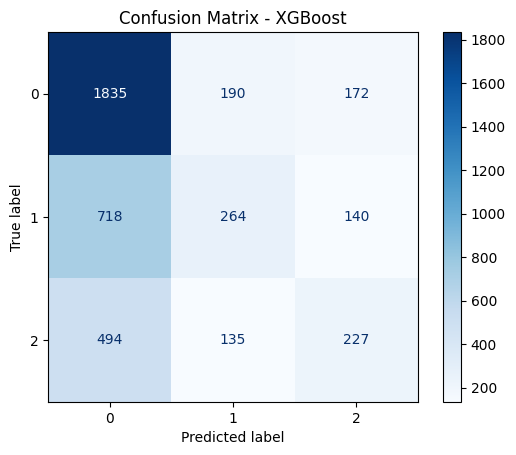

In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    random_state=42,
    n_estimators=100,
    eval_metric='mlogloss',

)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)

print('XGBoost F1 Score:', f1_score(y_test, y_pred_xgb, average='weighted'))
print('\nClassification Report:')
print(classification_report(y_test, y_pred_xgb))

ConfusionMatrixDisplay.from_estimator(xgb_model, X_test, y_test, cmap='Blues')
plt.title('Confusion Matrix - XGBoost')
plt.show()

XGBoost differs from Random Forest in a key way - it builds trees sequentially rather than independently
Each new tree specifically focuses on correcting the mistakes made by the previous tree
This sequential learning makes it more powerful on structured tabular data like this survey dataset
XGBoost achieved the highest weighted F1 of 0.52 outperforming all previous models

# MODEL 5B - XGBOOST (TUNED)

In [ ]:
xgb_model_tuned = XGBClassifier(
    random_state=42,
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    eval_metric='mlogloss',
    subsample=0.8,
    colsample_bytree=0.8
)

xgb_model_tuned.fit(X_train, y_train)
y_pred_tuned = xgb_model_tuned.predict(X_test)

print('Tuned XGBoost F1 Score:', f1_score(y_test, y_pred_tuned, average='weighted'))
print('\nClassification Report:')
print(classification_report(y_test, y_pred_tuned))



Tuned XGBoost F1 Score: 0.5231186062916421

Classification Report:
              precision    recall  f1-score   support

           0       0.61      0.84      0.71      2197
           1       0.46      0.24      0.31      1122
           2       0.43      0.27      0.33       856

    accuracy                           0.56      4175
   macro avg       0.50      0.45      0.45      4175
weighted avg       0.53      0.56      0.52      4175



After identifying XGBoost as the best performing model we attempted hyperparameter tuning to push performance further
Parameters adjusted:
- n_estimators increased from 100 to 200 (more trees)
- max_depth set to 6 (control tree complexity)
- learning_rate set to 0.1 (how fast the model learns)
- subsample set to 0.8 (use 80% of data per tree)
- colsample_bytree set to 0.8 (use 80% of features per tree)
Result: F1 of 0.5179 - marginally lower than default XGBoost

This confirms that default XGBoost settings are already well optimised for this dataset and the performance ceiling is driven by available features not model configuration

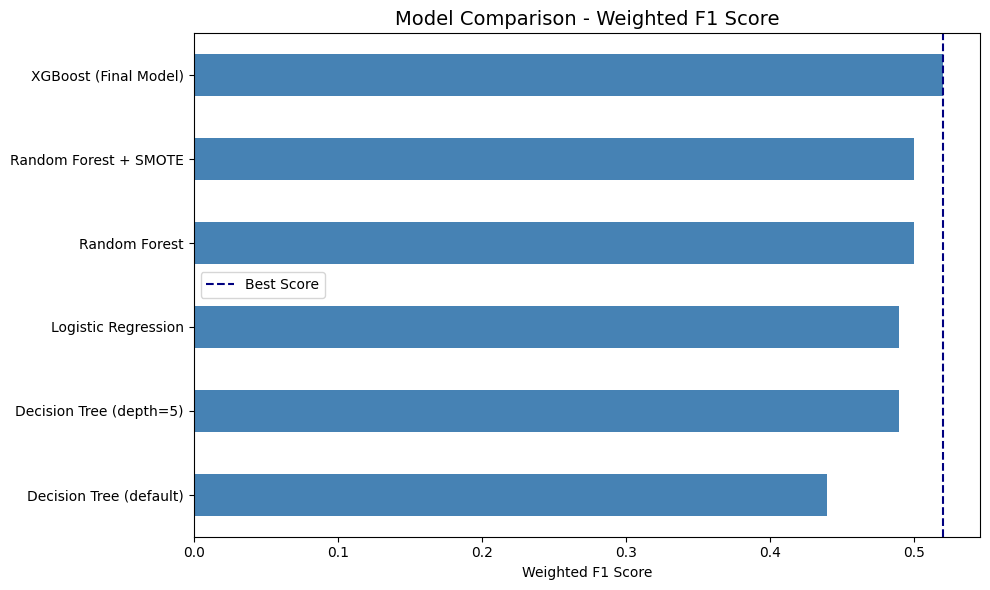

In [ ]:
# MODEL COMPARISON

results = {
    'Decision Tree (default)': 0.44,
    'Decision Tree (depth=5)': 0.49,
    'Logistic Regression': 0.49,
    'Random Forest': 0.50,
    'Random Forest + SMOTE': 0.50,
    'XGBoost (Final Model)': 0.52
}

results_df = pd.Series(results).sort_values()

results_df.plot(kind='barh', figsize=(10, 6), color='steelblue')
plt.title('Model Comparison - Weighted F1 Score', fontsize=14)
plt.xlabel('Weighted F1 Score')
plt.axvline(x=0.52, color='navy', linestyle='--', label='Best Score')
plt.legend()
plt.tight_layout()
plt.show()

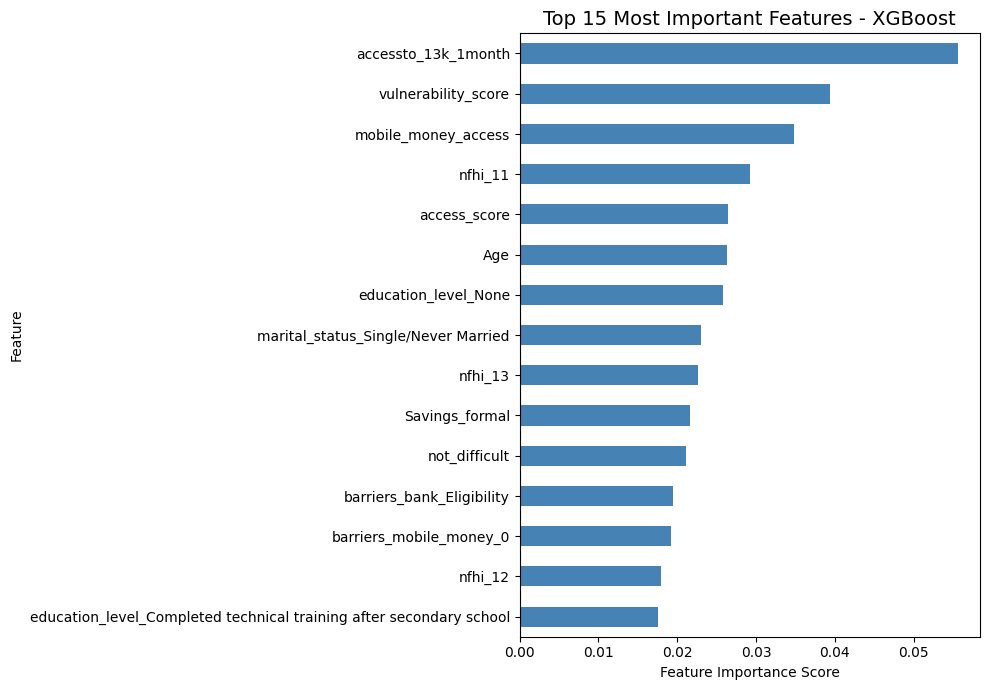

In [ ]:
# FEATURE IMPORTANCES - XGBOOST
# Which features does the model rely on most to make
# predictions? This answers the guiding question:
# "Which factors most strongly predict financial status?"

importances = pd.Series(
    xgb_model.feature_importances_,
    index=X.columns
).sort_values(ascending=True).tail(15)

importances.plot(kind='barh', figsize=(10, 7), color='steelblue')

plt.title('Top 15 Most Important Features - XGBoost', fontsize=14)
plt.xlabel('Feature Importance Score')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()
